# Customer Segmentation Using Clustering Algorithms
## UCI Online Retail Dataset

**Course:** 23CSE301 Machine Learning Capstone  
**Track:** Clustering (Unsupervised Learning)

### Problem statement
Identify groups of customers with similar purchasing behaviour using transaction data, without using predefined labels during model fitting.

### Objectives
1. Inspect and clean the Online Retail transaction dataset.
2. Create customer-level purchasing features.
3. Apply K-Means and Agglomerative Hierarchical Clustering.
4. Evaluate both algorithms with the required internal metrics.
5. Visualise clusters using PCA and t-SNE.
6. Profile the customer segments and discuss limitations.

**Dataset:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail)

**Dataset loading note:** This notebook expects a CSV file named `Online_Retail.csv` in the same folder as this notebook. If your file has another name or is in another folder, update `DATA_PATH` in the loading cell. If your downloaded file is Excel (`.xlsx`), use `pd.read_excel()` instead of `pd.read_csv()`.


## 1. Import libraries and set a random seed

In [1]:
# Libraries for data processing
import os
import warnings
import numpy as np
import pandas as pd

# Libraries for visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Clustering algorithms and evaluation metrics
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Feature scaling and dimensionality reduction
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Hierarchical clustering dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram

# Set a fixed seed for reproducible random operations
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the CSV dataset and inspect it
The variable used throughout this notebook is **`df`**. This avoids the earlier `df_raw` versus `df` NameError.

In [4]:
# Enter the name/path of your downloaded CSV file here.


# Read the CSV file into the DataFrame named df.
# If your CSV uses a different filename or folder, update DATA_PATH above.

df = pd.read_excel("Online Retail.xlsx")

# Display the first rows and dataset dimensions.
print("Dataset shape:", df.shape)
display(df.head())

# Inspect data types and non-null counts.
print("\nData types and non-null counts:")
df.info()

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [5]:
# Inspect column names, missing values, unique values and duplicate rows.
print("Column names:")
print(df.columns.tolist())

audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(audit)

print("Exact duplicate rows:", df.duplicated().sum())

# Check that expected columns exist before later processing.
required_columns = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(
        f"Expected columns are missing: {missing_columns}. "
        "Check that you loaded the UCI Online Retail CSV file."
    )

# Convert InvoiceDate to datetime for date-based analysis.
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

display(df.describe(include="all").T)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,dtype,missing_count,missing_percent,unique_values
InvoiceNo,object,0,0.00,25900
StockCode,object,0,0.00,4070
Description,object,1454,0.27,4223
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[us],0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,float64,135080,24.93,4372
Country,str,0,0.00,38


Exact duplicate rows: 5268
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Clean the transaction data

For the main segmentation analysis:
- Remove rows without `CustomerID` because they cannot be assigned to an identified customer.
- Remove exact duplicate rows.
- Exclude cancellation invoices whose invoice number starts with `C`.
- Exclude non-positive quantities and prices so the segments describe positive purchases.
- Calculate transaction-line value as `Quantity × UnitPrice`.

These choices define the scope of this project; they should be mentioned as limitations because cancellations and returns are meaningful business events.

In [6]:
# Work on a separate cleaned DataFrame while preserving the originally loaded df.
clean_df = df.copy()

# Normalise key data types and remove invalid key values.
clean_df["InvoiceNo"] = clean_df["InvoiceNo"].astype(str).str.strip()
clean_df["CustomerID"] = pd.to_numeric(clean_df["CustomerID"], errors="coerce")
clean_df["Quantity"] = pd.to_numeric(clean_df["Quantity"], errors="coerce")
clean_df["UnitPrice"] = pd.to_numeric(clean_df["UnitPrice"], errors="coerce")
clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"], errors="coerce")

rows_before = len(clean_df)

# Remove rows missing fields needed for customer-level purchase features.
clean_df = clean_df.dropna(
    subset=["CustomerID", "InvoiceDate", "Quantity", "UnitPrice"]
)

# Remove exact duplicates.
clean_df = clean_df.drop_duplicates()

# Exclude cancellation invoices (invoice number starts with C).
is_cancellation = clean_df["InvoiceNo"].str.upper().str.startswith("C")
cancellations_removed = int(is_cancellation.sum())
clean_df = clean_df.loc[~is_cancellation].copy()

# Exclude returns/adjustments and non-positive prices from positive-purchase profiles.
nonpositive_mask = (
    (clean_df["Quantity"] <= 0) | (clean_df["UnitPrice"] <= 0)
)
nonpositive_removed = int(nonpositive_mask.sum())
clean_df = clean_df.loc[~nonpositive_mask].copy()

# CustomerID is an identifier; cast it to integer after dropping missing IDs.
clean_df["CustomerID"] = clean_df["CustomerID"].astype("int64")

# Calculate the purchase value of each line.
clean_df["LineValue"] = clean_df["Quantity"] * clean_df["UnitPrice"]

print(f"Rows at start: {rows_before:,}")
print(f"Rows after cleaning: {len(clean_df):,}")
print(f"Cancellation rows excluded: {cancellations_removed:,}")
print(f"Rows with non-positive quantity/price excluded: {nonpositive_removed:,}")
print(f"Unique customers remaining: {clean_df['CustomerID'].nunique():,}")
print("Missing values in key analysis columns:")
display(clean_df[
    ["CustomerID", "InvoiceDate", "Quantity", "UnitPrice", "LineValue"]
].isna().sum())

Rows at start: 541,909
Rows after cleaning: 392,692
Cancellation rows excluded: 8,872
Rows with non-positive quantity/price excluded: 40
Unique customers remaining: 4,338
Missing values in key analysis columns:


CustomerID     0
InvoiceDate    0
Quantity       0
UnitPrice      0
LineValue      0
dtype: int64

## 4. Exploratory data analysis (EDA)
Plots below help examine the transaction distributions and business context. Interpret them using the outputs from your run.

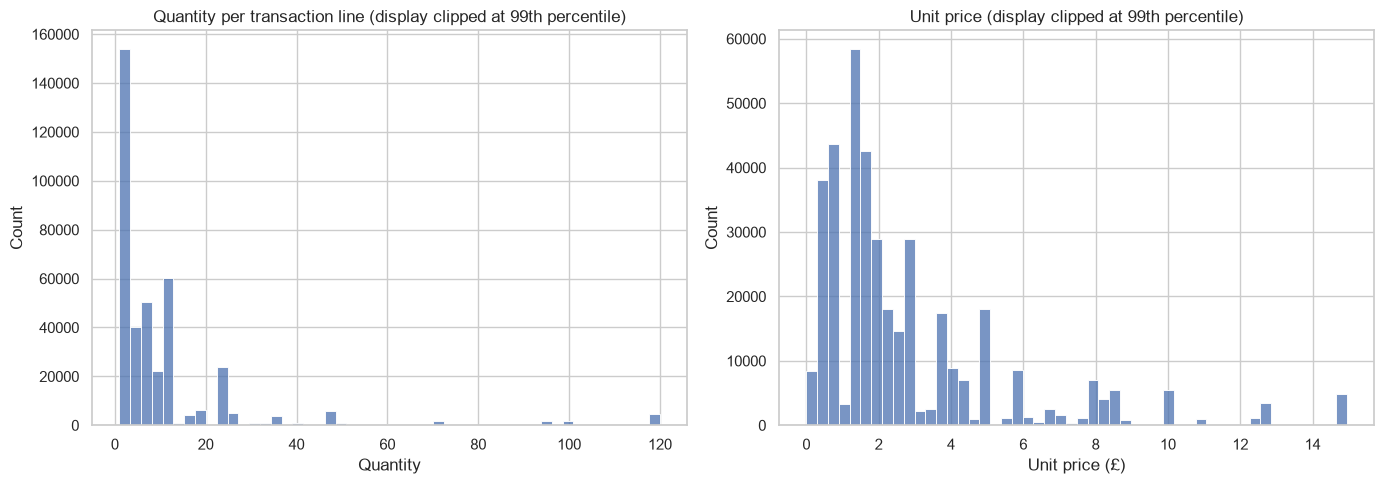

In [7]:
# Plot transaction quantity and unit-price distributions.
# Clip only for visualisation so extreme values do not hide the main distribution.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

quantity_cap = clean_df["Quantity"].quantile(0.99)
price_cap = clean_df["UnitPrice"].quantile(0.99)

sns.histplot(clean_df["Quantity"].clip(upper=quantity_cap), bins=50, ax=axes[0])
axes[0].set_title("Quantity per transaction line (display clipped at 99th percentile)")
axes[0].set_xlabel("Quantity")

sns.histplot(clean_df["UnitPrice"].clip(upper=price_cap), bins=50, ax=axes[1])
axes[1].set_title("Unit price (display clipped at 99th percentile)")
axes[1].set_xlabel("Unit price (£)")

plt.tight_layout()
plt.show()

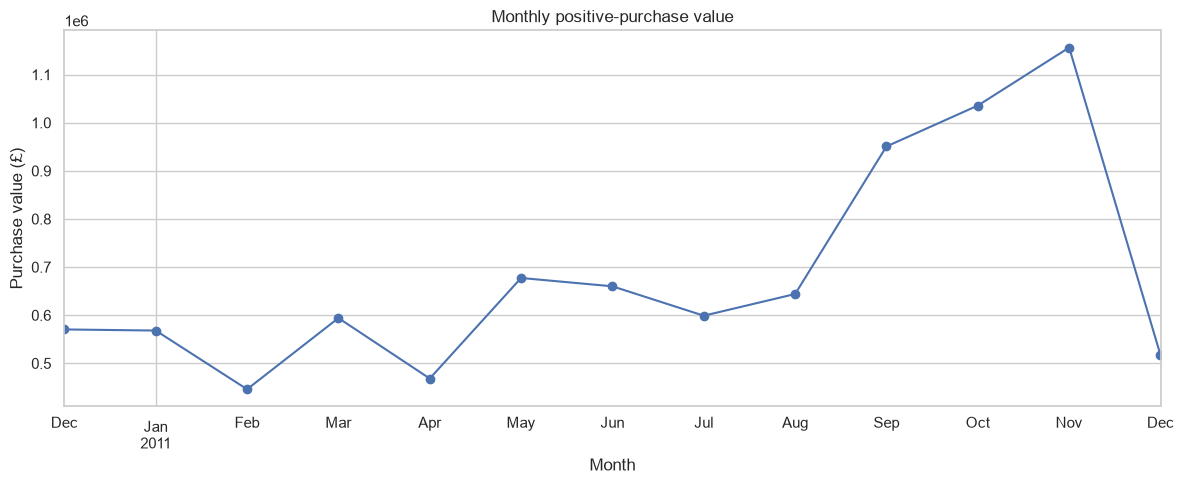

,MonthlySalesGBP
InvoiceDate,
2010-12-01,570422.730
2011-01-01,568101.310
2011-02-01,446084.920
2011-03-01,594081.760
2011-04-01,468374.331
2011-05-01,677355.150
2011-06-01,660046.050
2011-07-01,598962.901
2011-08-01,644051.040


In [8]:
# Summarise monthly positive purchase value.
monthly_sales = (
    clean_df.set_index("InvoiceDate")
    .resample("MS")["LineValue"]
    .sum()
)

plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly positive-purchase value")
plt.xlabel("Month")
plt.ylabel("Purchase value (£)")
plt.tight_layout()
plt.show()

display(monthly_sales.rename("MonthlySalesGBP").to_frame())

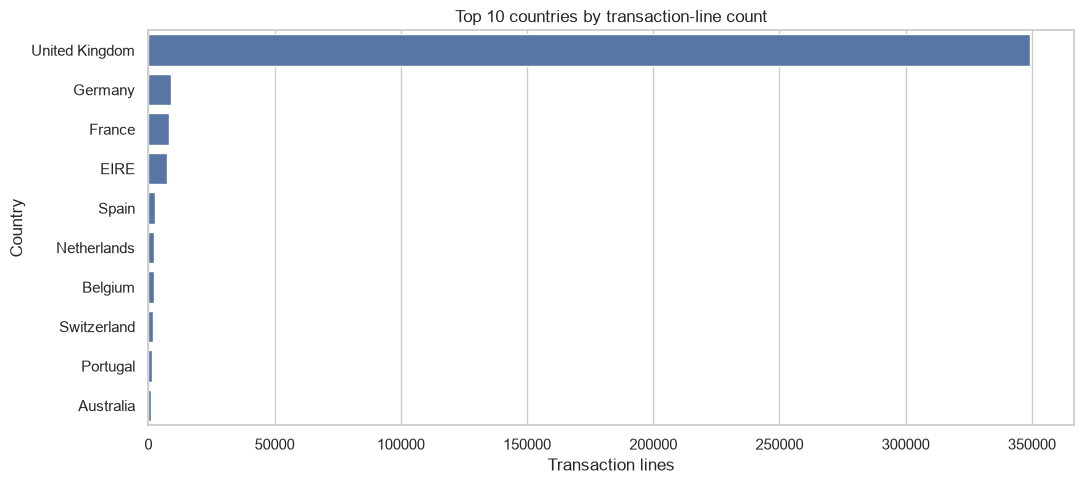

In [9]:
# Display the 10 countries with the most transaction lines.
# Country is used for descriptive EDA only, not as a clustering feature.
top_countries = clean_df["Country"].value_counts().head(10)

plt.figure(figsize=(11, 5))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 countries by transaction-line count")
plt.xlabel("Transaction lines")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### EDA observations

After running the notebook, add short observations based on the plots: distribution skew, monthly variation, and concentration of transaction activity by country. Do not claim a pattern unless your generated output supports it.

## 5. Engineer customer-level features
Create one row per customer. Recency uses the day after the last transaction in the cleaned dataset as its reference date.

In [10]:
# Use the day after the latest observed transaction as the reference date.
reference_date = clean_df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

# Aggregate transaction lines into customer-level purchase features.
customer_features = clean_df.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),  # Number of distinct invoices
    Monetary=("LineValue", "sum"),       # Total positive purchase value
    AverageQuantity=("Quantity", "mean"),
    AverageUnitPrice=("UnitPrice", "mean"),
    TotalItems=("Quantity", "sum"),
    Country=("Country", lambda values: (
        values.mode().iloc[0] if not values.mode().empty else "Unknown"
    ))
).reset_index()

# Recency: days between the reference date and each customer's last purchase date.
customer_features["Recency"] = (
    reference_date - customer_features["LastPurchase"].dt.normalize()
).dt.days

print("Reference date for Recency:", reference_date.date())
print("Customer-level dataset shape:", customer_features.shape)
display(customer_features.head())

feature_columns = [
    "Recency", "Frequency", "Monetary",
    "AverageQuantity", "AverageUnitPrice"
]
display(customer_features[feature_columns].describe().T)

Reference date for Recency: 2011-12-10
Customer-level dataset shape: (4338, 9)


,CustomerID,LastPurchase,Frequency,Monetary,AverageQuantity,AverageUnitPrice,TotalItems,Country,Recency
0,12346,2011-01-18 10:01:00,1,77183.60,74215.000000,1.040000,74215,United Kingdom,326
1,12347,2011-12-07 15:52:00,7,4310.00,13.505495,2.644011,2458,Iceland,3
2,12348,2011-09-25 13:13:00,4,1797.24,75.516129,5.764839,2341,Finland,76
3,12349,2011-11-21 09:51:00,1,1757.55,8.643836,8.289041,631,Italy,19
4,12350,2011-02-02 16:01:00,1,334.40,11.588235,3.841176,197,Norway,311


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,93.059474,100.012264,1.0000,18.000000,51.000000,142.750000,374.00
Frequency,4338.0,4.272015,7.697998,1.0000,1.000000,2.000000,5.000000,209.00
Monetary,4338.0,2048.688081,8985.230220,3.7500,306.482500,668.570000,1660.597500,280206.02
AverageQuantity,4338.0,45.080599,1203.437983,1.0000,6.042120,10.000000,14.666667,74215.00
AverageUnitPrice,4338.0,4.470820,34.215024,0.1225,2.206415,2.917836,3.832541,2033.10


## 6. Transform and scale the features
The clustering algorithms use numerical behavioural features only. `CustomerID`, `LastPurchase` and `Country` are retained for interpretation but excluded from model input. `log1p` reduces right skew before standardisation.

In [11]:
# Keep only the chosen numerical behavioural features for modelling.
model_df = customer_features.replace([np.inf, -np.inf], np.nan).dropna(
    subset=feature_columns
).copy()

# Check non-negativity before log1p transformation.
if (model_df[feature_columns] < 0).any().any():
    raise ValueError("Negative values found in selected features; review cleaning first.")

# Apply log1p to reduce skew in customer-level features.
X_log = np.log1p(model_df[feature_columns])

# Standardise features so each has comparable scale for distance-based algorithms.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Customers used for clustering:", X_scaled.shape[0])
print("Features used:", feature_columns)

Customers used for clustering: 4338
Features used: ['Recency', 'Frequency', 'Monetary', 'AverageQuantity', 'AverageUnitPrice']


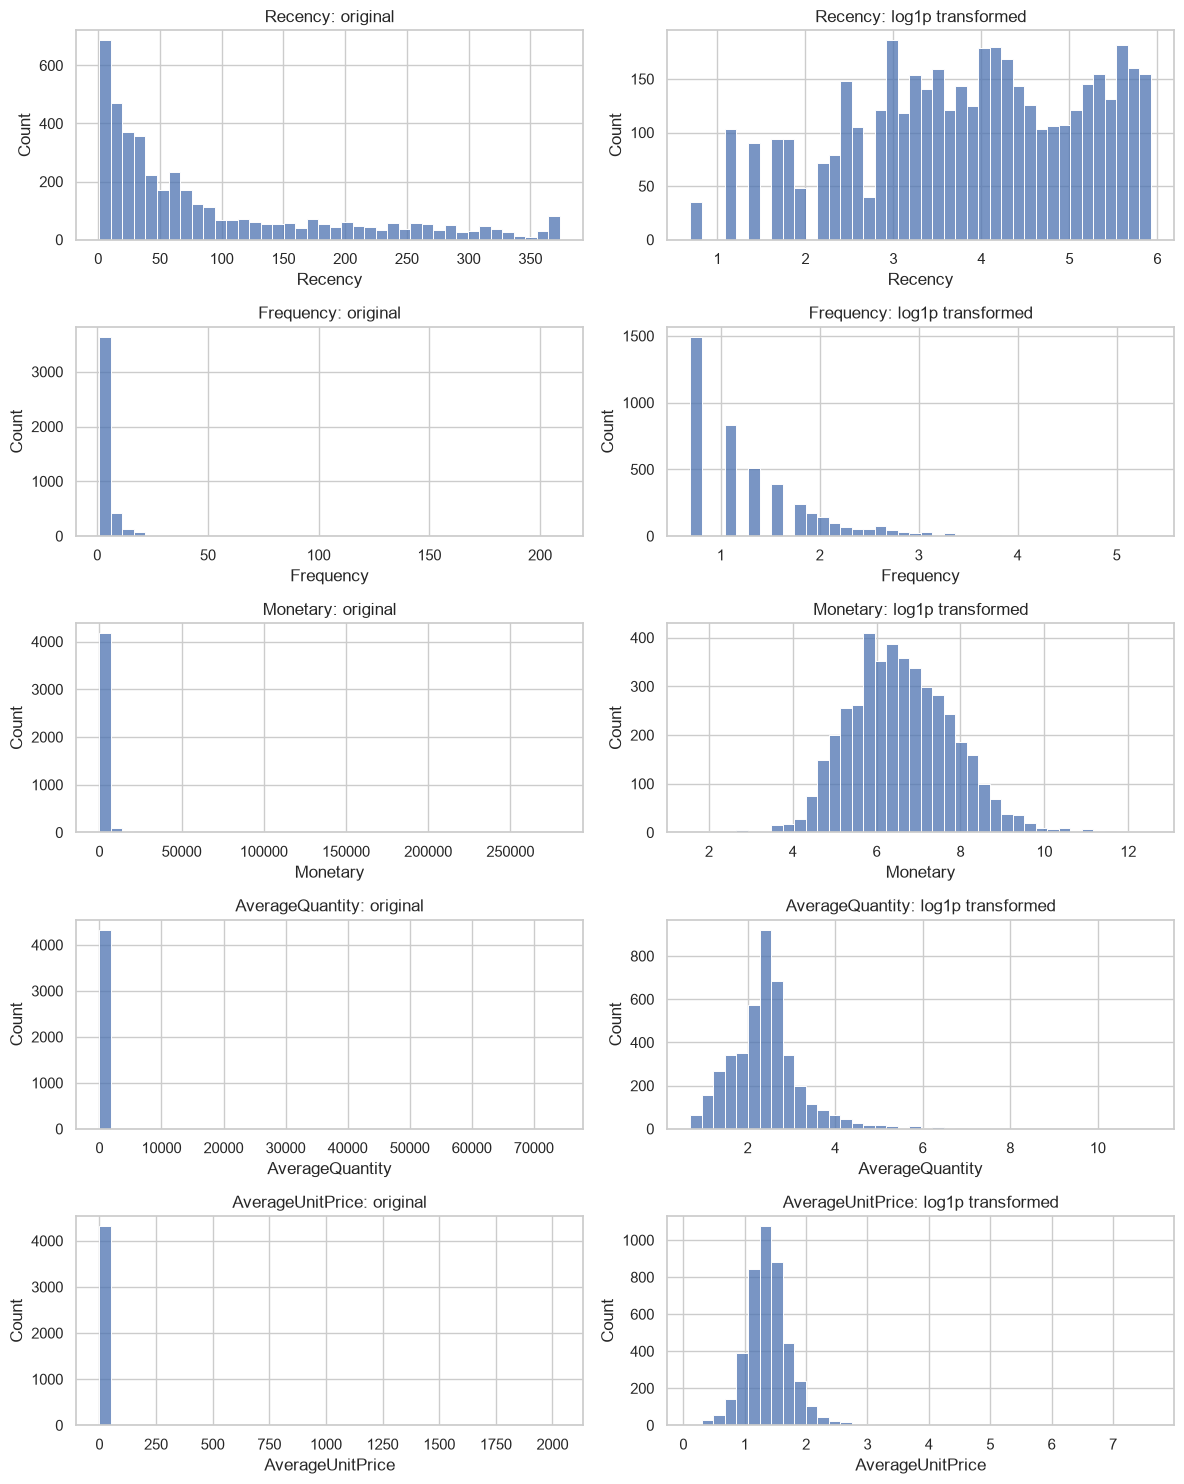

In [12]:
# Compare original and log-transformed feature distributions.
fig, axes = plt.subplots(len(feature_columns), 2, figsize=(12, 3 * len(feature_columns)))

for i, column in enumerate(feature_columns):
    sns.histplot(model_df[column], bins=40, ax=axes[i, 0])
    axes[i, 0].set_title(f"{column}: original")
    sns.histplot(X_log[column], bins=40, ax=axes[i, 1])
    axes[i, 1].set_title(f"{column}: log1p transformed")

plt.tight_layout()
plt.show()

## 7. K-Means clustering and Elbow curve
Try `k` values from 2 to 10. The Elbow curve is mandatory; silhouette scores provide an additional comparison. Review both plots when choosing the final number of clusters.

In [13]:
# Fit K-Means for each candidate k and record inertia and silhouette score.
k_values = range(2, 11)
kmeans_results = []

for k in k_values:
    candidate = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    candidate_labels = candidate.fit_predict(X_scaled)

    kmeans_results.append({
        "k": k,
        "Inertia": candidate.inertia_,
        "Silhouette": silhouette_score(X_scaled, candidate_labels)
    })

kmeans_tuning = pd.DataFrame(kmeans_results)
display(kmeans_tuning.round(4))

,k,Inertia,Silhouette
0,2,15101.5111,0.3001
1,3,13115.9464,0.2303
2,4,11570.3676,0.2051
3,5,10389.1936,0.2145
4,6,9539.0234,0.1986
5,7,8755.1452,0.1976
6,8,8127.4907,0.1953
7,9,7664.9851,0.1801
8,10,7330.9023,0.1798


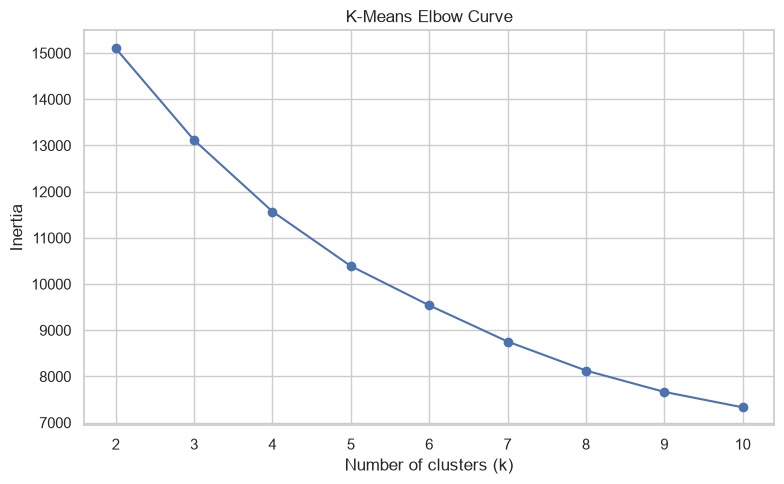

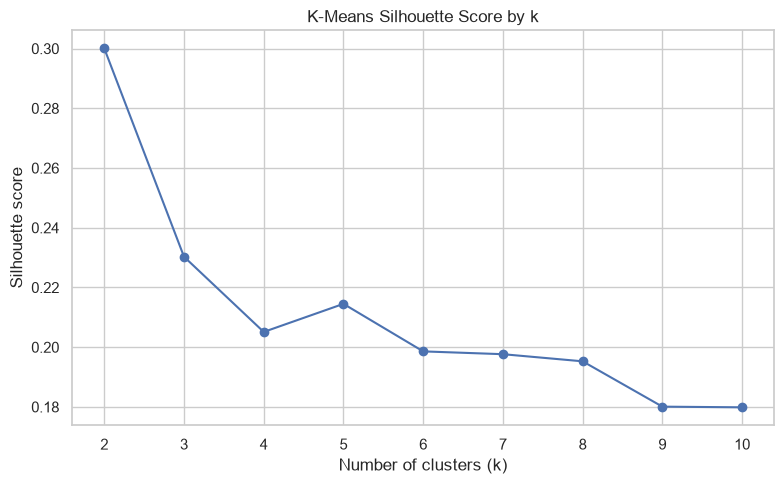

In [14]:
# Elbow curve: inertia generally decreases as the number of clusters increases.
plt.figure(figsize=(8, 5))
plt.plot(kmeans_tuning["k"], kmeans_tuning["Inertia"], marker="o")
plt.title("K-Means Elbow Curve")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

# Supporting metric: silhouette score (higher is generally better).
plt.figure(figsize=(8, 5))
plt.plot(kmeans_tuning["k"], kmeans_tuning["Silhouette"], marker="o")
plt.title("K-Means Silhouette Score by k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

### Select K-Means cluster count

The next cell selects the candidate with the highest silhouette score as a starting point. Check the Elbow curve as well; if you choose a different `k`, update `selected_k` and explain your reasoning.

In [15]:
# Initial reproducible choice: highest silhouette score among tested k values.
selected_k = int(
    kmeans_tuning.loc[kmeans_tuning["Silhouette"].idxmax(), "k"]
)
print("Initial selected k:", selected_k)

# Fit the final K-Means model with the chosen cluster count.
kmeans_model = KMeans(
    n_clusters=selected_k,
    random_state=RANDOM_STATE,
    n_init=10
)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

model_df["KMeansCluster"] = kmeans_labels
print("K-Means cluster sizes:")
display(model_df["KMeansCluster"].value_counts().sort_index())

Initial selected k: 2
K-Means cluster sizes:


KMeansCluster
0    1645
1    2693
Name: count, dtype: int64

## 8. Agglomerative Hierarchical Clustering and linkage comparison
Compare Ward, complete and average linkage at the same cluster count. Ward uses Euclidean distance and seeks compact clusters.

In [ ]:
# Fit Agglomerative Clustering with each linkage option.
linkage_results = []
linkage_labels = {}

for linkage_name in ["ward", "complete", "average"]:
    candidate = AgglomerativeClustering(
        n_clusters=selected_k,
        linkage=linkage_name
    )
    labels = candidate.fit_predict(X_scaled)
    linkage_labels[linkage_name] = labels

    linkage_results.append({
        "Linkage": linkage_name,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels)
    })

linkage_comparison = pd.DataFrame(linkage_results).sort_values(
    "Silhouette", ascending=False
)
display(linkage_comparison.round(4))

,Linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz
1,complete,0.7473,0.5808,177.3478
2,average,0.7473,0.5808,177.3478
0,ward,0.2506,1.4306,1479.2158


### Select the final linkage
The next cell chooses the linkage with the highest silhouette score as an initial choice. Review all three metrics and cluster sizes before finalising.

In [ ]:
# Initial linkage choice based on silhouette score; change if results justify it.
selected_linkage = str(linkage_comparison.iloc[0]["Linkage"])
print("Initial selected linkage:", selected_linkage)

agglomerative_model = AgglomerativeClustering(
    n_clusters=selected_k,
    linkage=selected_linkage
)
agglomerative_labels = agglomerative_model.fit_predict(X_scaled)

model_df["AgglomerativeCluster"] = agglomerative_labels
print("Agglomerative cluster sizes:")
display(model_df["AgglomerativeCluster"].value_counts().sort_index())

Initial selected linkage: complete
Agglomerative cluster sizes:


AgglomerativeCluster
0    4330
1       8
Name: count, dtype: int64

## 9. Dendrogram visualisation

A dendrogram for every customer can be hard to read, so this plot uses a reproducible sample of up to 500 customers. The final clustering comparison above uses all rows in `X_scaled`. The sample dendrogram is illustrative and may not exactly represent the full dataset's hierarchy.

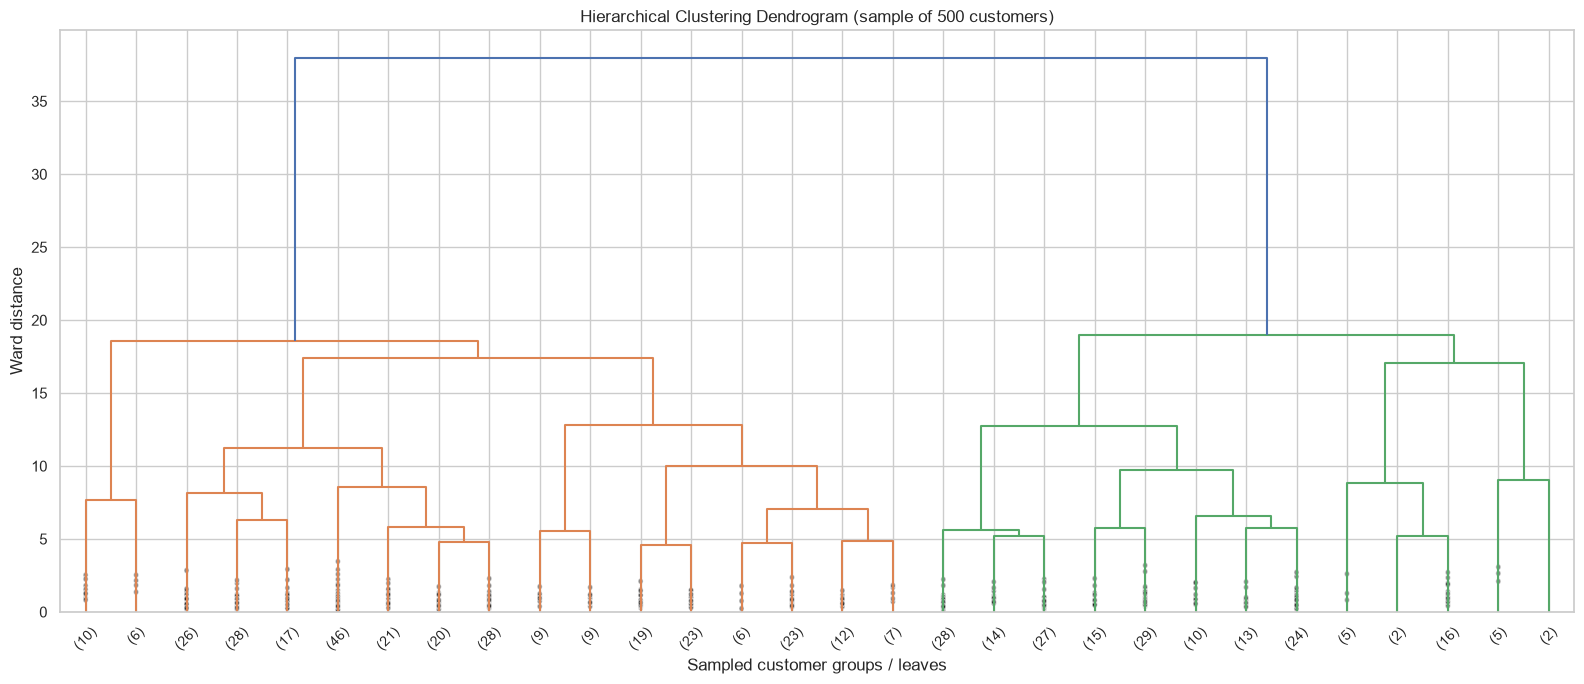

In [ ]:
# Draw a dendrogram from a manageable sample of customers.
dendrogram_n = min(500, len(X_scaled))
rng = np.random.RandomState(RANDOM_STATE)
sample_indices = rng.choice(len(X_scaled), size=dendrogram_n, replace=False)
X_dendrogram = X_scaled[sample_indices]

# Ward linkage is used for this dendrogram visualisation.
Z = linkage(X_dendrogram, method="ward", metric="euclidean")

plt.figure(figsize=(16, 7))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=10,
    show_contracted=True
)
plt.title(f"Hierarchical Clustering Dendrogram (sample of {dendrogram_n} customers)")
plt.xlabel("Sampled customer groups / leaves")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

## 10. Evaluate and compare both algorithms
All three required metrics are calculated on the same scaled customer features. Higher Silhouette and Calinski–Harabasz scores are generally preferred; a lower Davies–Bouldin score is generally preferred.

In [ ]:
# Calculate the required internal evaluation metrics for both final algorithms.
evaluation_rows = []

for algorithm_name, labels in [
    ("K-Means", kmeans_labels),
    (f"Agglomerative ({selected_linkage})", agglomerative_labels)
]:
    evaluation_rows.append({
        "Algorithm": algorithm_name,
        "Clusters": len(np.unique(labels)),
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_scaled, labels)
    })

evaluation_table = pd.DataFrame(evaluation_rows)
display(evaluation_table.round(4))

,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,2,0.3001,1.2850,1891.7134
1,Agglomerative (complete),2,0.7473,0.5808,177.3478


## 11. PCA visualisations for both algorithms
PCA projects the scaled features into two dimensions for visualisation. The models themselves were fitted using all selected features.

Explained variance ratio: [0.4605 0.2373]
Total variance explained by two components: 0.6978


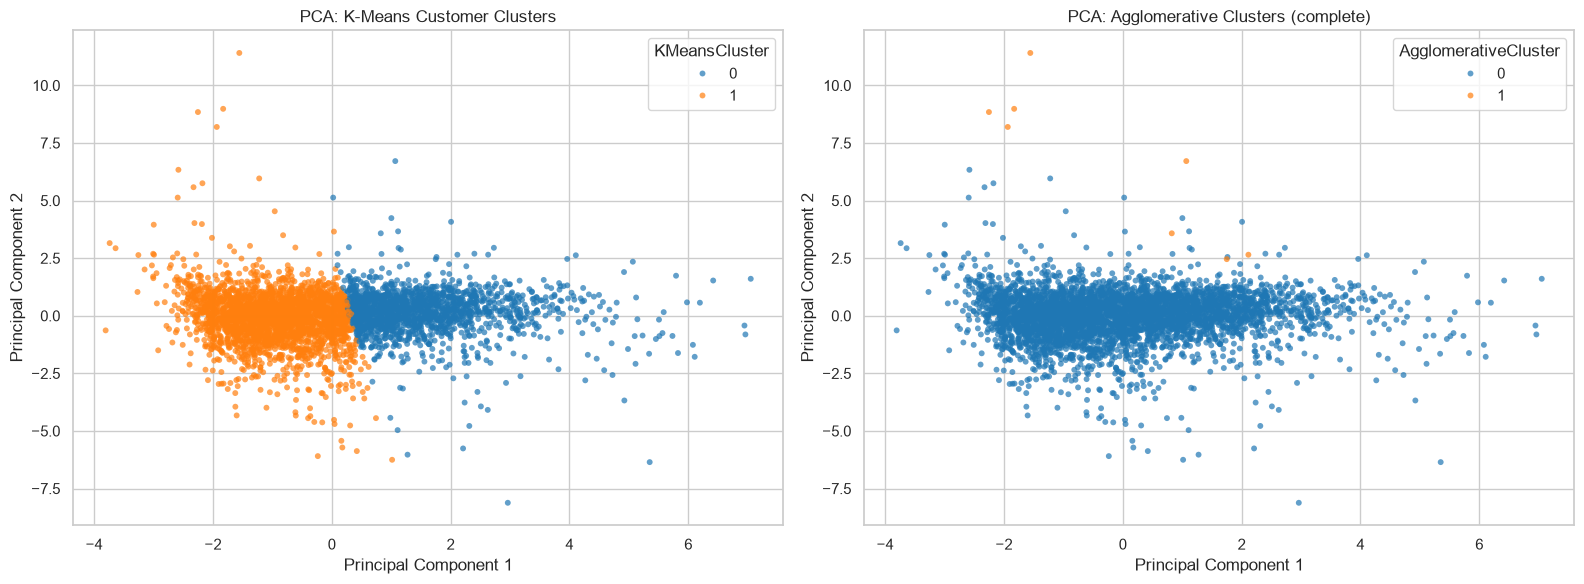

In [ ]:
# Reduce the feature matrix to two principal components.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("Total variance explained by two components:",
      round(pca.explained_variance_ratio_.sum(), 4))

pca_plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeansCluster": kmeans_labels.astype(str),
    "AgglomerativeCluster": agglomerative_labels.astype(str)
})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=pca_plot_df, x="PC1", y="PC2",
    hue="KMeansCluster", palette="tab10",
    s=18, alpha=0.7, linewidth=0, ax=axes[0]
)
axes[0].set_title("PCA: K-Means Customer Clusters")

sns.scatterplot(
    data=pca_plot_df, x="PC1", y="PC2",
    hue="AgglomerativeCluster", palette="tab10",
    s=18, alpha=0.7, linewidth=0, ax=axes[1]
)
axes[1].set_title(f"PCA: Agglomerative Clusters ({selected_linkage})")

for ax in axes:
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

## 12. t-SNE visualisation

t-SNE can reveal local neighbourhood structure in a nonlinear 2D projection. Its plot should be treated as a visual aid, not as proof of cluster quality. To keep execution practical, this section uses up to 2,000 sampled customers.

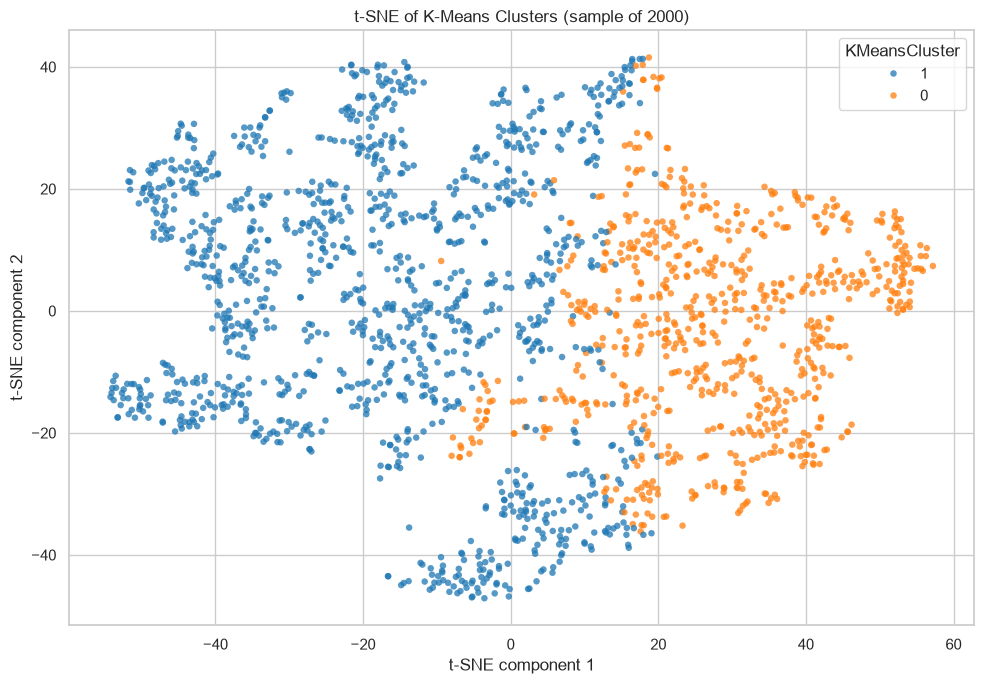

In [ ]:
# Sample customers for t-SNE to reduce runtime.
tsne_n = min(2000, len(X_scaled))
rng = np.random.RandomState(RANDOM_STATE)
tsne_indices = rng.choice(len(X_scaled), size=tsne_n, replace=False)

X_tsne_input = X_scaled[tsne_indices]
tsne_labels = kmeans_labels[tsne_indices].astype(str)

# Perplexity must be smaller than the number of samples.
tsne_perplexity = min(30, max(5, (tsne_n - 1) // 3))

tsne = TSNE(
    n_components=2,
    perplexity=tsne_perplexity,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE
)
X_tsne = tsne.fit_transform(X_tsne_input)

tsne_plot_df = pd.DataFrame({
    "tSNE1": X_tsne[:, 0],
    "tSNE2": X_tsne[:, 1],
    "KMeansCluster": tsne_labels
})

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=tsne_plot_df, x="tSNE1", y="tSNE2",
    hue="KMeansCluster", palette="tab10",
    s=22, alpha=0.75, linewidth=0
)
plt.title(f"t-SNE of K-Means Clusters (sample of {tsne_n})")
plt.xlabel("t-SNE component 1")
plt.ylabel("t-SNE component 2")
plt.tight_layout()
plt.show()

## 13. Customer cluster profiling and interpretation
Compare original-unit customer features by cluster. Cluster numbers are arbitrary labels; describe each group from its measured profile rather than assuming a specific meaning.

In [ ]:
# Profile K-Means clusters using customer-level features in original units.
profile_features = [
    "Recency", "Frequency", "Monetary",
    "AverageQuantity", "AverageUnitPrice", "TotalItems"
]

kmeans_profile = model_df.groupby("KMeansCluster").agg(
    CustomerCount=("CustomerID", "count"),
    **{f"{col}_mean": (col, "mean") for col in profile_features},
    **{
        f"{col}_median": (col, "median")
        for col in ["Recency", "Frequency", "Monetary", "TotalItems"]
    }
).round(2)

display(kmeans_profile)

# Profile Agglomerative clusters with the same features.
agg_profile = model_df.groupby("AgglomerativeCluster").agg(
    CustomerCount=("CustomerID", "count"),
    **{f"{col}_mean": (col, "mean") for col in profile_features},
    **{
        f"{col}_median": (col, "median")
        for col in ["Recency", "Frequency", "Monetary", "TotalItems"]
    }
).round(2)

display(agg_profile)

,CustomerCount,Recency_mean,Frequency_mean,Monetary_mean,AverageQuantity_mean,AverageUnitPrice_mean,TotalItems_mean,Recency_median,Frequency_median,Monetary_median,TotalItems_median
KMeansCluster,,,,,,,,,,,
0,1645,26.73,8.50,4594.98,87.51,3.90,2648.36,17.0,6.0,2089.85,1227.0
1,2693,133.58,1.69,493.31,19.16,4.82,295.37,95.0,1.0,363.79,205.0


,CustomerCount,Recency_mean,Frequency_mean,Monetary_mean,AverageQuantity_mean,AverageUnitPrice_mean,TotalItems_mean,Recency_median,Frequency_median,Monetary_median,TotalItems_median
AgglomerativeCluster,,,,,,,,,,,
0,4330,93.02,4.27,2039.53,44.49,3.49,1186.07,51.0,2.0,668.50,378.0
1,8,117.00,3.38,7004.84,367.12,537.30,2038.00,92.5,2.0,3026.57,61.5


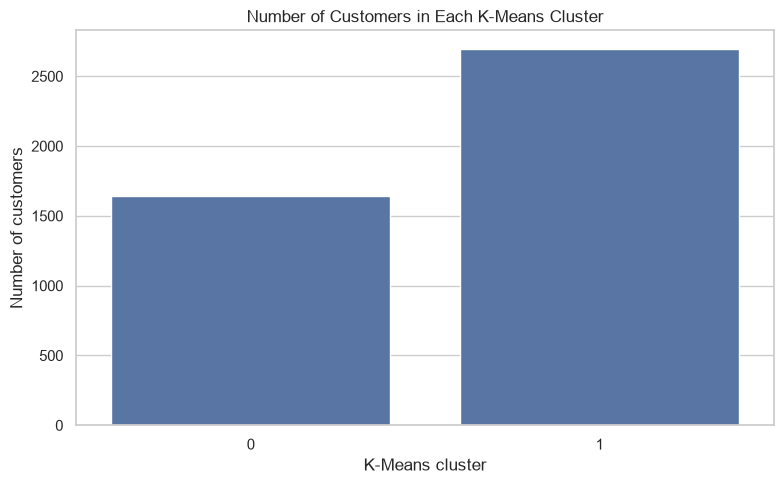

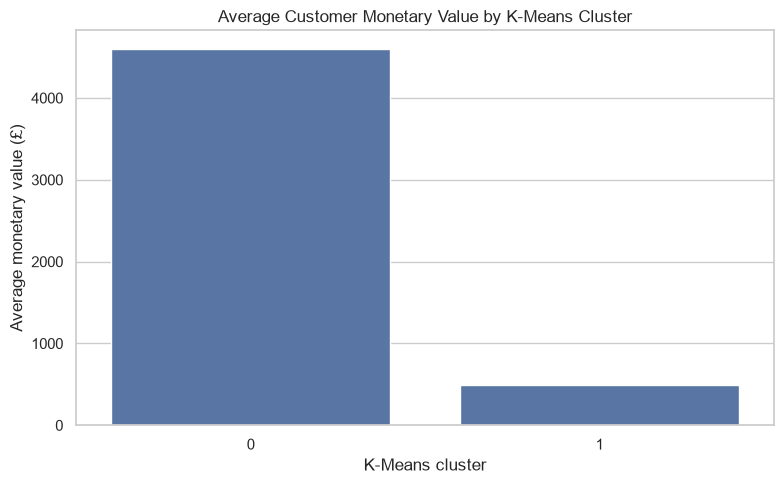

In [ ]:
# Visualise the number of customers in each K-Means cluster.
cluster_sizes = model_df["KMeansCluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=cluster_sizes.index.astype(str), y=cluster_sizes.values)
plt.title("Number of Customers in Each K-Means Cluster")
plt.xlabel("K-Means cluster")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

# Compare mean monetary value between K-Means clusters.
monetary_means = model_df.groupby("KMeansCluster")["Monetary"].mean()

plt.figure(figsize=(8, 5))
sns.barplot(x=monetary_means.index.astype(str), y=monetary_means.values)
plt.title("Average Customer Monetary Value by K-Means Cluster")
plt.xlabel("K-Means cluster")
plt.ylabel("Average monetary value (£)")
plt.tight_layout()
plt.show()

### Cluster interpretation notes

Use the generated profiles to describe each cluster. Check Recency, Frequency and Monetary values together. A cluster with lower recency values purchased more recently; a cluster with higher frequency has more distinct invoices; a cluster with higher monetary value spent more over the observed period. These are descriptions of historical data, not guaranteed predictions of future customer behaviour.

## 14. Final comparison, conclusion and limitations

The following table consolidates the final results. Use the actual metrics, visualisations and profiles to make your conclusion; do not choose a winning algorithm based on only one metric.

In [ ]:
# Consolidated final comparison table.
final_comparison = evaluation_table.copy()
final_comparison["Configuration"] = [
    f"k={selected_k}",
    f"k={selected_k}, linkage={selected_linkage}"
]

final_comparison = final_comparison[
    [
        "Algorithm", "Configuration", "Clusters",
        "Silhouette Score", "Davies-Bouldin Index",
        "Calinski-Harabasz Index"
    ]
]

display(final_comparison.round(4))

print("Customers included in clustering:", len(model_df))
print("\nK-Means cluster sizes:")
display(model_df["KMeansCluster"].value_counts().sort_index())
print("\nAgglomerative cluster sizes:")
display(model_df["AgglomerativeCluster"].value_counts().sort_index())

,Algorithm,Configuration,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,k=2,2,0.3001,1.2850,1891.7134
1,Agglomerative (complete),"k=2, linkage=complete",2,0.7473,0.5808,177.3478


Customers included in clustering: 4338

K-Means cluster sizes:


KMeansCluster
0    1645
1    2693
Name: count, dtype: int64


Agglomerative cluster sizes:


AgglomerativeCluster
0    4330
1       8
Name: count, dtype: int64

### Conclusion template — complete after running

- **Data preparation:** Report the transaction rows and unique customers retained after cleaning.
- **Feature engineering:** Explain why Recency, Frequency, Monetary value and supporting behavioural features were selected.
- **K-Means:** State the selected cluster count and what the Elbow curve suggested.
- **Agglomerative clustering:** State the selected linkage and what the dendrogram revealed.
- **Evaluation:** Compare Silhouette, Davies–Bouldin and Calinski–Harabasz scores, noting any trade-offs.
- **Customer segments:** Describe the profiles supported by the actual summary tables.
- **Business relevance:** Explain how the segments could inform marketing or customer-retention analysis, while noting that further validation is needed.

### Limitations

1. The dataset represents a historical period (2010–2011), so segments may not represent present-day customer behaviour.
2. Rows without CustomerID cannot be included in customer-level clustering.
3. Excluding cancellations and non-positive quantities focuses this analysis on positive purchases and omits returns behaviour.
4. Results depend on feature definitions, reference date, transformation and scaling.
5. K-Means and hierarchical clustering can be affected by outliers and feature choices.
6. PCA and t-SNE are projections and may not preserve all structure in the original feature space.
7. Internal metrics alone do not prove that the segments are commercially useful.

### References

- Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33
- [Scikit-learn KMeans documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Scikit-learn AgglomerativeClustering documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html)
- [Scikit-learn clustering evaluation](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation)

**Academic integrity:** Write your final observations and conclusions from the results generated by your own run, and acknowledge AI assistance in your README if your course guidelines require it.


In [ ]:
%pip install streamlit joblib plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\monithaa\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\monithaa\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 976.6 kB/s eta 0:00:10
   --- ------------------------------------ 0.8/9.7 MB 904.7 kB/s eta 0:00:10
   --- ------------------------------------ 0.8/9.7 MB 904.7 kB/s eta 0:00:10
   ---- ----------------------------------- 1.0/9.7 MB 890.0 kB/s eta 0:00:10
   ----- ---------------------------------- 1.3/9.7 MB 882.6 kB/s eta 0:00:10
   ----- ---------------------------------- 1.3/9.7 MB 882.6 kB/s eta 0:00:10
   ------ --------------------------------- 1.6/9.7 MB 918.0 kB/s eta 0:00:09
   ------- -------------------------------- 1.8/9.7 MB 902.8 kB/s eta 0:00:09
   ------- -------------------------------- 1.8/9.7 MB 902.8 kB/s eta 0:00:09
   -------- ----------

In [ ]:
import streamlit as st
import joblib

print("Streamlit setup successful!")
print("Streamlit version:", st.__version__)

^C
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import joblib, json, os
os.makedirs("model_artifacts", exist_ok=True)

joblib.dump(scaler,       "model_artifacts/scaler.pkl")
joblib.dump(pca,          "model_artifacts/pca.pkl")
joblib.dump(kmeans_model, "model_artifacts/kmeans.pkl")

model_df.to_csv("model_artifacts/customer_clusters.csv", index=False)
kmeans_profile.to_csv("model_artifacts/kmeans_profile.csv")
agg_profile.to_csv("model_artifacts/agg_profile.csv")
kmeans_tuning.to_csv("model_artifacts/kmeans_tuning.csv", index=False)
evaluation_table.to_csv("model_artifacts/evaluation_table.csv", index=False)
linkage_comparison.to_csv("model_artifacts/linkage_comparison.csv", index=False)
pca_plot_df.to_csv("model_artifacts/pca_coords.csv", index=False)

metadata = {
    "feature_columns": feature_columns,
    "selected_k": int(selected_k),
    "selected_linkage": str(selected_linkage),
    "n_customers": int(len(model_df)),
    "reference_date": str(reference_date.date()),
    "explained_variance": [float(v) for v in pca.explained_variance_ratio_],
    "total_variance_explained": float(pca.explained_variance_ratio_.sum()),
    "kmeans_metrics": {
        "silhouette": float(evaluation_table.loc[0, "Silhouette Score"]),
        "davies_bouldin": float(evaluation_table.loc[0, "Davies-Bouldin Index"]),
        "calinski_harabasz": float(evaluation_table.loc[0, "Calinski-Harabasz Index"]),
    },
    "agg_metrics": {
        "silhouette": float(evaluation_table.loc[1, "Silhouette Score"]),
        "davies_bouldin": float(evaluation_table.loc[1, "Davies-Bouldin Index"]),
        "calinski_harabasz": float(evaluation_table.loc[1, "Calinski-Harabasz Index"]),
    },
    "kmeans_cluster_sizes": {str(k): int(v) for k, v in model_df["KMeansCluster"].value_counts().sort_index().items()},
    "agg_cluster_sizes":    {str(k): int(v) for k, v in model_df["AgglomerativeCluster"].value_counts().sort_index().items()},
    "transaction_rows_after_cleaning": int(len(clean_df)),
    "unique_customers": int(clean_df["CustomerID"].nunique()),
    "date_range": [str(clean_df["InvoiceDate"].min()), str(clean_df["InvoiceDate"].max())],
}
with open("model_artifacts/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print("✅ Artifacts saved:", os.listdir("model_artifacts"))

✅ Artifacts saved: ['agg_profile.csv', 'customer_clusters.csv', 'evaluation_table.csv', 'kmeans.pkl', 'kmeans_profile.csv', 'kmeans_tuning.csv', 'linkage_comparison.csv', 'metadata.json', 'pca.pkl', 'pca_coords.csv', 'scaler.pkl']


In [ ]:
%%writefile app.py
"""
Customer Segmentation Dashboard — Animated UI, Fixed Dark Mode & Sidebar
"""
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st
import streamlit.components.v1 as components

st.set_page_config(
    page_title="Customer Segmentation",
    page_icon="🛍️",
    layout="wide",
    initial_sidebar_state="expanded",
)

# ======================================================================
# SESSION STATE
# ======================================================================
if "dark" not in st.session_state:
    st.session_state.dark = False
if "page" not in st.session_state:
    st.session_state.page = "🏠 Overview"

# ======================================================================
# THEME VARIABLES
# ======================================================================
if st.session_state.dark:
    BG_APP       = "linear-gradient(180deg, #0f172a 0%, #1e1b4b 100%)"
    BG_APP_SOLID = "#0f172a"
    BG_CARD      = "#1e293b"
    BG_CARD_2    = "#334155"
    TEXT_MAIN    = "#f1f5f9"
    TEXT_MUTED   = "#94a3b8"
    BORDER       = "#334155"
    SIDEBAR_BG   = "#0f172a"
    HOVER_ACCENT = "rgba(59,130,246,0.18)"
    CHART_BG     = "rgba(0,0,0,0)"
else:
    BG_APP       = "linear-gradient(180deg, #f8fafc 0%, #eef2ff 100%)"
    BG_APP_SOLID = "#f8fafc"
    BG_CARD      = "#ffffff"
    BG_CARD_2    = "#f8fafc"
    TEXT_MAIN    = "#0f172a"
    TEXT_MUTED   = "#64748b"
    BORDER       = "#e2e8f0"
    SIDEBAR_BG   = "#ffffff"
    HOVER_ACCENT = "rgba(59,130,246,0.08)"
    CHART_BG     = "rgba(0,0,0,0)"

# ======================================================================
# GLOBAL STYLES
# ======================================================================
st.markdown(f"""
<style>
    html, body, [class*="css"] {{
        font-family: 'Inter', 'Segoe UI', -apple-system, sans-serif;
    }}

    /* ---------- Force backgrounds everywhere ---------- */
    .stApp, .stApp > div,
    [data-testid="stAppViewContainer"],
    [data-testid="stAppViewContainer"] > .main,
    [data-testid="stAppViewContainer"] > section,
    .main, .block-container {{
        background: {BG_APP} !important;
        background-attachment: fixed !important;
        color: {TEXT_MAIN} !important;
    }}
    [data-testid="stHeader"], header[data-testid="stHeader"], [data-testid="stToolbar"] {{
        background: transparent !important;
    }}
    .block-container {{
        padding-top: 1.5rem; padding-bottom: 3rem; max-width: 1350px;
        animation: pageIn 0.6s ease-out;
    }}
    .stApp, .stApp p, .stApp span, .stApp div, .stApp label,
    .stMarkdown, .stMarkdown p, .stText,
    [data-testid="stMarkdownContainer"],
    [data-testid="stMarkdownContainer"] * {{
        color: {TEXT_MAIN};
    }}
    [data-testid="stCaptionContainer"],
    [data-testid="stCaptionContainer"] *,
    .stCaption, small {{
        color: {TEXT_MUTED} !important;
    }}

    /* ---------- Keyframes ---------- */
    @keyframes pageIn {{
        from {{ opacity: 0; transform: translateY(12px); }}
        to   {{ opacity: 1; transform: translateY(0); }}
    }}
    @keyframes fadeUp {{
        from {{ opacity: 0; transform: translateY(20px); }}
        to   {{ opacity: 1; transform: translateY(0); }}
    }}
    @keyframes glowPulse {{
        0%, 100% {{ box-shadow: 0 0 0 0 rgba(59,130,246,0.4); }}
        50%      {{ box-shadow: 0 0 0 12px rgba(59,130,246,0); }}
    }}
    @keyframes gradientShift {{
        0%, 100% {{ background-position: 0% 50%; }}
        50%      {{ background-position: 100% 50%; }}
    }}
    @keyframes floatOrb {{
        from {{ transform: rotate(0deg); }}
        to   {{ transform: rotate(360deg); }}
    }}
    @keyframes blink {{ 50% {{ opacity: 0; }} }}

    h1, h2, h3, h4, h5, h6 {{ color: {TEXT_MAIN} !important; }}

    /* ---------- METRIC CARDS ---------- */
    div[data-testid="stMetric"] {{
        background: {BG_CARD} !important;
        border: 1px solid {BORDER} !important;
        border-radius: 16px; padding: 20px 22px;
        box-shadow: 0 1px 3px rgba(15,23,42,0.06);
        transition: all 0.35s cubic-bezier(0.4, 0, 0.2, 1);
        position: relative; overflow: hidden;
        animation: fadeUp 0.5s ease-out backwards;
    }}
    div[data-testid="stMetric"]::before {{
        content: ''; position: absolute;
        top: 0; left: 0; right: 0; height: 3px;
        background: linear-gradient(90deg, #3b82f6, #8b5cf6, #ec4899);
        transform: scaleX(0); transform-origin: left;
        transition: transform 0.4s ease;
    }}
    div[data-testid="stMetric"]:hover {{
        transform: translateY(-4px);
        box-shadow: 0 12px 24px -8px rgba(15,23,42,0.15);
        border-color: #cbd5e1;
    }}
    div[data-testid="stMetric"]:hover::before {{ transform: scaleX(1); }}
    div[data-testid="stMetricLabel"], div[data-testid="stMetricLabel"] * {{
        color: {TEXT_MUTED} !important;
        font-size: 0.8rem; font-weight: 500;
        text-transform: uppercase; letter-spacing: 0.05em;
    }}
    div[data-testid="stMetricValue"], div[data-testid="stMetricValue"] * {{
        color: {TEXT_MAIN} !important;
        font-weight: 700; font-size: 1.75rem;
    }}

    /* ---------- SIDEBAR BASE ---------- */
    section[data-testid="stSidebar"],
    section[data-testid="stSidebar"] > div,
    [data-testid="stSidebarContent"],
    [data-testid="stSidebarUserContent"] {{
        background: {SIDEBAR_BG} !important;
        color: {TEXT_MAIN} !important;
    }}
    section[data-testid="stSidebar"] * {{ color: {TEXT_MAIN}; }}
    section[data-testid="stSidebar"] hr {{ border-color: {BORDER} !important; }}
    section[data-testid="stSidebar"] [data-testid="stWidgetLabel"],
    section[data-testid="stSidebar"] [data-testid="stWidgetLabel"] * {{
        color: {TEXT_MAIN} !important;
    }}

    /* ============================================================
       SIDEBAR RADIO — FIXED COMPACT LAYOUT
       ============================================================ */
    section[data-testid="stSidebar"] .stRadio > div,
    section[data-testid="stSidebar"] div[role="radiogroup"] {{
        display: flex !important;
        flex-direction: column !important;
        gap: 2px !important;
    }}
    section[data-testid="stSidebar"] div[role="radiogroup"] > label,
    section[data-testid="stSidebar"] .stRadio label {{
        display: flex !important;
        flex-direction: row !important;
        align-items: center !important;
        justify-content: flex-start !important;
        padding: 6px 10px !important;
        margin: 0 !important;
        border-radius: 8px !important;
        gap: 8px !important;
        min-height: 36px !important;
        height: auto !important;
        line-height: 1.2 !important;
        transition: background 0.2s ease !important;
        background: transparent !important;
        width: 100% !important;
    }}
    section[data-testid="stSidebar"] div[role="radiogroup"] > label > div:first-child,
    section[data-testid="stSidebar"] .stRadio label > div:first-child {{
        transform: scale(0.75) !important;
        margin: 0 !important;
        flex-shrink: 0 !important;
        flex-grow: 0 !important;
        width: auto !important;
    }}
    section[data-testid="stSidebar"] div[role="radiogroup"] > label > div:last-child,
    section[data-testid="stSidebar"] .stRadio label > div:last-child {{
        margin: 0 !important;
        padding: 0 !important;
        font-size: 0.9rem !important;
        white-space: nowrap !important;
        color: {TEXT_MAIN} !important;
        flex-grow: 1 !important;
    }}
    section[data-testid="stSidebar"] div[role="radiogroup"] > label:hover {{
        background: {HOVER_ACCENT} !important;
    }}
    /* Kill the tall spacing between radio items */
    section[data-testid="stSidebar"] .stRadio [data-baseweb="radio"] {{
        margin: 0 !important;
        padding: 0 !important;
    }}

    /* ---------- BUTTONS ---------- */
    .stButton > button, .stDownloadButton > button, .stFormSubmitButton > button {{
        border-radius: 10px; font-weight: 600;
        border: 1px solid {BORDER} !important;
        background: {BG_CARD} !important;
        color: {TEXT_MAIN} !important;
        padding: 10px 22px;
        transition: all 0.25s cubic-bezier(0.4, 0, 0.2, 1);
    }}
    .stButton > button:hover, .stDownloadButton > button:hover,
    .stFormSubmitButton > button:hover {{
        background: linear-gradient(135deg, #3b82f6, #8b5cf6) !important;
        color: #ffffff !important;
        border-color: transparent !important;
        transform: translateY(-2px);
        box-shadow: 0 8px 16px -4px rgba(59,130,246,0.5);
    }}

    /* ---------- INPUTS ---------- */
    .stTextInput input, .stNumberInput input,
    .stSelectbox div[data-baseweb="select"],
    .stMultiSelect div[data-baseweb="select"] {{
        background: {BG_CARD} !important;
        color: {TEXT_MAIN} !important;
        border: 1px solid {BORDER} !important;
        border-radius: 10px !important;
    }}
    .stTextInput input::placeholder, .stNumberInput input::placeholder {{
        color: {TEXT_MUTED} !important;
        opacity: 0.7;
    }}
    div[data-baseweb="popover"] ul,
    div[data-baseweb="popover"] li {{
        background: {BG_CARD} !important;
        color: {TEXT_MAIN} !important;
    }}

    /* ---------- DATAFRAMES / ALERTS / SPINNERS ---------- */
    .stDataFrame {{
        border-radius: 12px; overflow: hidden;
        border: 1px solid {BORDER} !important;
        animation: fadeUp 0.5s ease-out;
        background: {BG_CARD} !important;
    }}
    .stAlert {{
        border-radius: 12px; animation: fadeUp 0.4s ease-out;
        color: {TEXT_MAIN} !important;
    }}
    [data-testid="stSpinner"] {{ color: {TEXT_MAIN} !important; }}

    /* ---------- HERO ---------- */
    .hero {{
        background: linear-gradient(135deg, #1e293b 0%, #334155 50%, #1e40af 100%);
        background-size: 200% 200%;
        color: white; padding: 44px 48px;
        border-radius: 20px; margin-bottom: 28px;
        position: relative; overflow: hidden;
        animation: heroSlide 0.8s cubic-bezier(0.4, 0, 0.2, 1),
                   gradientShift 12s ease infinite;
    }}
    @keyframes heroSlide {{
        from {{ opacity: 0; transform: translateY(-20px) scale(0.98); }}
        to   {{ opacity: 1; transform: translateY(0) scale(1); }}
    }}
    .hero::after {{
        content: ''; position: absolute;
        top: -50%; right: -50%; width: 100%; height: 200%;
        background: radial-gradient(circle, rgba(255,255,255,0.08) 0%, transparent 60%);
        animation: floatOrb 20s linear infinite;
    }}
    .hero h1 {{
        color: white !important; margin: 0;
        font-size: 2.2rem; font-weight: 800;
        letter-spacing: -0.02em;
        position: relative; z-index: 1; min-height: 2.6rem;
    }}
    .hero .cursor {{
        display: inline-block; width: 3px; height: 2rem;
        background: #60a5fa; margin-left: 4px;
        vertical-align: -4px;
        animation: blink 1s step-end infinite;
    }}
    .hero p {{
        color: #cbd5e1 !important; margin-top: 10px;
        font-size: 1.1rem;
        position: relative; z-index: 1;
    }}
    .hero .badge {{
        display: inline-block;
        background: rgba(255,255,255,0.15);
        backdrop-filter: blur(8px);
        padding: 6px 14px; border-radius: 999px;
        font-size: 0.8rem; font-weight: 600;
        margin-top: 16px;
        position: relative; z-index: 1;
        border: 1px solid rgba(255,255,255,0.2);
        color: white !important;
    }}

    /* ---------- CHIP ---------- */
    .chip {{
        display: inline-block; padding: 6px 16px;
        border-radius: 999px; font-size: 0.9rem;
        font-weight: 700; color: white !important;
        box-shadow: 0 4px 12px rgba(0,0,0,0.15);
        animation: glowPulse 2s ease-in-out infinite;
    }}

    /* ---------- SECTION HEADERS ---------- */
    .section-anchor {{ scroll-margin-top: 90px; }}
    .section-header {{
        display: flex; align-items: center; gap: 10px;
        margin: 28px 0 16px 0;
        animation: fadeUp 0.5s ease-out;
    }}
    .section-header .icon {{ font-size: 1.5rem; }}
    .section-header .title {{
        font-size: 1.35rem; font-weight: 700;
        color: {TEXT_MAIN} !important;
        letter-spacing: -0.02em;
    }}
    .section-header .line {{
        flex: 1; height: 1px;
        background: linear-gradient(90deg, {BORDER}, transparent);
    }}

    /* ---------- TOP PROGRESS BAR ---------- */
    .top-progress {{
        position: fixed; top: 0; left: 0;
        height: 3px; width: 0%;
        background: linear-gradient(90deg, #3b82f6, #8b5cf6, #ec4899);
        z-index: 9999;
        transition: width 0.4s ease, opacity 0.4s ease;
        box-shadow: 0 0 12px rgba(59,130,246,0.6);
    }}

    html {{ scroll-behavior: smooth; }}

    /* ---------- DARK MODE OVERRIDES ---------- */
    {'[data-testid="stAppViewContainer"] > .main { background: #0f172a !important; }' if st.session_state.dark else ''}
    {'section[data-testid="stSidebar"] { background: #0f172a !important; }' if st.session_state.dark else ''}
    {'div[data-testid="stMetric"] { background: #1e293b !important; border-color: #334155 !important; }' if st.session_state.dark else ''}
    {'div[data-testid="stMetricLabel"] * { color: #94a3b8 !important; }' if st.session_state.dark else ''}
    {'div[data-testid="stMetricValue"] * { color: #f1f5f9 !important; }' if st.session_state.dark else ''}
    {'section[data-testid="stSidebar"] div[role="radiogroup"] > label > div:last-child { color: #f1f5f9 !important; }' if st.session_state.dark else ''}
    {'h1, h2, h3, h4, h5, h6 { color: #f1f5f9 !important; }' if st.session_state.dark else ''}
    {'p, span, label, div { color: #f1f5f9 !important; }' if st.session_state.dark else ''}
    {'[data-testid="stCaptionContainer"] * { color: #94a3b8 !important; }' if st.session_state.dark else ''}
    {'[data-testid="stMarkdownContainer"] * { color: #f1f5f9 !important; }' if st.session_state.dark else ''}
</style>
""", unsafe_allow_html=True)

# ======================================================================
# TOP PROGRESS BAR
# ======================================================================
components.html("""
<div id="topProgress" class="top-progress"></div>
<script>
  (function () {
    const bar = document.getElementById('topProgress');
    if (!bar) return;
    bar.style.width = '0%';
    bar.style.opacity = '1';
    let w = 0;
    const tick = setInterval(() => {
      w += 12 + Math.random() * 20;
      if (w >= 100) {
        w = 100;
        clearInterval(tick);
        setTimeout(() => { bar.style.opacity = '0'; }, 250);
      }
      bar.style.width = w + '%';
    }, 90);
  })();
</script>
<style>
.top-progress {
  position: fixed; top: 0; left: 0; height: 3px; width: 0%;
  background: linear-gradient(90deg,#3b82f6,#8b5cf6,#ec4899);
  z-index: 99999; transition: width .4s ease, opacity .4s ease;
  box-shadow: 0 0 12px rgba(59,130,246,.6);
}
</style>
""", height=0)

# ======================================================================
# HELPERS
# ======================================================================
def section_header(icon, title, anchor=None):
    anchor_attr = f'id="{anchor}"' if anchor else ""
    st.markdown(f"""
    <div class="section-anchor" {anchor_attr}></div>
    <div class="section-header">
        <span class="icon">{icon}</span>
        <span class="title">{title}</span>
        <span class="line"></span>
    </div>
    """, unsafe_allow_html=True)

def confetti():
    components.html("""
    <html><head>
    <script src="https://cdn.jsdelivr.net/npm/canvas-confetti@1.9.0/dist/confetti.browser.min.js"></script>
    </head><body>
    <script>
      (function(){
        const duration = 1800;
        const end = Date.now() + duration;
        (function frame(){
          confetti({ particleCount: 4, angle: 60, spread: 55, origin: { x: 0 },
            colors: ['#3b82f6','#8b5cf6','#ec4899','#f59e0b'] });
          confetti({ particleCount: 4, angle: 120, spread: 55, origin: { x: 1 },
            colors: ['#3b82f6','#8b5cf6','#ec4899','#f59e0b'] });
          if (Date.now() < end) requestAnimationFrame(frame);
        })();
      })();
    </script>
    </body></html>
    """, height=0)

def typed_hero(title, subtitle, badge):
    components.html(f"""
    <html><head>
    <style>
      body {{ margin: 0; font-family: 'Inter','Segoe UI',sans-serif; }}
      .hero {{
        background: linear-gradient(135deg, #1e293b 0%, #334155 50%, #1e40af 100%);
        background-size: 200% 200%; color: white;
        padding: 44px 48px; border-radius: 20px;
        position: relative; overflow: hidden;
        animation: gradientShift 12s ease infinite;
      }}
      @keyframes gradientShift {{
        0%,100% {{ background-position: 0% 50%; }}
        50%     {{ background-position: 100% 50%; }}
      }}
      .hero::after {{
        content:''; position:absolute; top:-50%; right:-50%;
        width:100%; height:200%;
        background: radial-gradient(circle, rgba(255,255,255,0.08) 0%, transparent 60%);
        animation: floatOrb 20s linear infinite;
      }}
      @keyframes floatOrb {{ from {{transform:rotate(0)}} to {{transform:rotate(360deg)}} }}
      .hero h1 {{
        margin: 0; font-size: 2.2rem; font-weight: 800;
        letter-spacing: -0.02em; color: white;
        position: relative; z-index: 1; min-height: 2.8rem;
      }}
      .cursor {{
        display: inline-block; width: 3px; height: 2rem;
        background: #60a5fa; margin-left: 4px;
        vertical-align: -4px;
        animation: blink 1s step-end infinite;
      }}
      @keyframes blink {{ 50% {{ opacity: 0; }} }}
      .hero p {{
        color: #cbd5e1; margin-top: 10px; font-size: 1.1rem;
        position: relative; z-index: 1; opacity: 0;
        animation: fadeUp 0.6s ease 2.4s forwards;
      }}
      .hero .badge {{
        display:inline-block; background: rgba(255,255,255,0.15);
        backdrop-filter: blur(8px); padding: 6px 14px;
        border-radius: 999px; font-size: 0.8rem; font-weight: 600;
        margin-top: 16px; position: relative; z-index: 1;
        border: 1px solid rgba(255,255,255,0.2); color: white;
        opacity: 0; animation: fadeUp 0.6s ease 2.8s forwards;
      }}
      @keyframes fadeUp {{
        from {{ opacity: 0; transform: translateY(10px); }}
        to   {{ opacity: 1; transform: translateY(0); }}
      }}
    </style></head>
    <body>
    <div class="hero">
      <h1><span id="typed"></span><span class="cursor"></span></h1>
      <p>{subtitle}</p>
      <span class="badge">{badge}</span>
    </div>
    <script>
      const text = "{title}";
      let i = 0;
      const el = document.getElementById("typed");
      function type() {{
        if (i < text.length) {{
          el.textContent += text.charAt(i);
          i++;
          setTimeout(type, 45);
        }}
      }}
      type();
    </script>
    </body></html>
    """, height=210)

def animated_metric(label, value_str, help_text=None):
    import re
    m = re.search(r"([\d,]+\.?\d*)", str(value_str))
    if not m:
        st.metric(label, value_str, help=help_text)
        return

    numeric = float(m.group(1).replace(",", ""))
    prefix = value_str[:m.start(1)]
    suffix = value_str[m.end(1):]
    has_dec = "true" if "." in m.group(1) else "false"

    components.html(f"""
    <html><head>
    <style>
      body {{ margin: 0; font-family: 'Inter','Segoe UI',sans-serif; }}
      .card {{
        background: {BG_CARD};
        border: 1px solid {BORDER};
        border-radius: 16px; padding: 20px 22px;
        box-shadow: 0 1px 3px rgba(15,23,42,0.06);
        position: relative; overflow: hidden;
        transition: all 0.35s ease;
      }}
      .card::before {{
        content:''; position:absolute; top:0;left:0;right:0;height:3px;
        background: linear-gradient(90deg,#3b82f6,#8b5cf6,#ec4899);
        transform: scaleX(0); transform-origin:left;
        transition: transform 0.4s ease;
      }}
      .card:hover {{ transform: translateY(-4px);
        box-shadow: 0 12px 24px -8px rgba(15,23,42,0.15);
        border-color:#cbd5e1; }}
      .card:hover::before {{ transform: scaleX(1); }}
      .lbl {{
        color: {TEXT_MUTED};
        font-size: 0.8rem; font-weight: 500;
        text-transform: uppercase;
        letter-spacing: 0.05em; margin-bottom: 6px;
      }}
      .val {{ color: {TEXT_MAIN}; font-weight: 700; font-size: 1.75rem; }}
    </style></head>
    <body>
    <div class="card">
      <div class="lbl">{label}</div>
      <div class="val"><span id="n"></span></div>
    </div>
    <script>
      const target = {numeric};
      const prefix = "{prefix}";
      const suffix = "{suffix}";
      const hasDecimals = {has_dec};
      const duration = 900;
      const start = performance.now();
      function fmt(v) {{
        if (hasDecimals) return v.toFixed(1);
        return Math.round(v).toLocaleString('en-US');
      }}
      function step(now) {{
        const t = Math.min(1, (now - start) / duration);
        const eased = 1 - Math.pow(1 - t, 3);
        const v = target * eased;
        document.getElementById('n').textContent = prefix + fmt(v) + suffix;
        if (t < 1) requestAnimationFrame(step);
        else document.getElementById('n').textContent = prefix + fmt(target) + suffix;
      }}
      requestAnimationFrame(step);
    </script>
    </body></html>
    """, height=115)

# ======================================================================
# LOAD DATA
# ======================================================================
ART = Path("model_artifacts")

@st.cache_data(show_spinner=False)
def load_metadata():
    with open(ART / "metadata.json") as f:
        return json.load(f)

@st.cache_data(show_spinner=False)
def load_customers():
    return pd.read_csv(ART / "customer_clusters.csv")

@st.cache_data(show_spinner=False)
def load_kmeans_profile():
    df = pd.read_csv(ART / "kmeans_profile.csv")
    return df.set_index(df.columns[0])

@st.cache_data(show_spinner=False)
def load_agg_profile():
    df = pd.read_csv(ART / "agg_profile.csv")
    return df.set_index(df.columns[0])

@st.cache_data(show_spinner=False)
def load_evaluation():
    return pd.read_csv(ART / "evaluation_table.csv")

@st.cache_data(show_spinner=False)
def load_kmeans_tuning():
    return pd.read_csv(ART / "kmeans_tuning.csv")

@st.cache_data(show_spinner=False)
def load_linkage():
    return pd.read_csv(ART / "linkage_comparison.csv")

@st.cache_data(show_spinner=False)
def load_pca():
    return pd.read_csv(ART / "pca_coords.csv")

@st.cache_resource(show_spinner=False)
def load_model():
    return joblib.load(ART / "scaler.pkl"), joblib.load(ART / "kmeans.pkl")

if not ART.exists() or not (ART / "metadata.json").exists():
    st.error("⚠️ Model artifacts not found. Please run the export cell in the notebook first.")
    st.stop()

with st.spinner("🔄 Loading model metadata..."):
    meta = load_metadata()
with st.spinner("📦 Loading customer clusters..."):
    customers = load_customers()
with st.spinner("📊 Building cluster profiles..."):
    kmeans_profile = load_kmeans_profile()
    agg_profile = load_agg_profile()
with st.spinner("📈 Loading evaluation metrics..."):
    evaluation = load_evaluation()
    kmeans_tuning = load_kmeans_tuning()
    linkage = load_linkage()
with st.spinner("🎨 Preparing PCA coordinates..."):
    pca_df = load_pca()
with st.spinner("🤖 Restoring trained model..."):
    scaler, kmeans_model = load_model()

FEATURES = meta["feature_columns"]
CLUSTER_COLORS = px.colors.qualitative.Set2

# ======================================================================
# SIDEBAR
# ======================================================================
with st.sidebar:
    st.markdown(f"""
    <div style='text-align:center; padding: 8px 0 16px 0;'>
        <div style='font-size: 2.2rem; margin-bottom: 4px;'>🛍️</div>
        <div style='font-weight: 800; font-size: 1.15rem; color:{TEXT_MAIN}; letter-spacing:-0.02em;'>
            Customer Segmentation
        </div>
        <div style='color:{TEXT_MUTED}; font-size: 0.8rem; margin-top: 4px;'>
            UCI Online Retail · ML Capstone
        </div>
    </div>
    """, unsafe_allow_html=True)

    st.markdown("---")

    dark_on = st.toggle("🌙 Dark mode", value=st.session_state.dark, key="dark_toggle")
    if dark_on != st.session_state.dark:
        st.session_state.dark = dark_on
        st.rerun()

    st.markdown("---")

    page = st.radio(
        "Navigate",
        [
            "🏠 Overview",
            "📊 Data & EDA",
            "🎯 Clustering Results",
            "📈 Model Comparison",
            "🗺️ Visualizations",
            "🧑‍💼 Customer Profiler",
            "🔮 Predict New Customer",
        ],
        label_visibility="collapsed",
        key="page_radio",
    )
    st.session_state.page = page

    st.markdown("---")
    st.markdown(f"""
    <div style='padding: 8px 0;'>
        <div style='color:{TEXT_MUTED}; font-size: 0.75rem; text-transform: uppercase; letter-spacing: 0.05em; margin-bottom: 8px;'>
            Quick stats
        </div>
        <div style='display:flex; justify-content:space-between; padding: 4px 0; font-size: 0.85rem;'>
            <span style='color:{TEXT_MUTED};'>Customers</span>
            <span style='color:{TEXT_MAIN}; font-weight:600;'>{meta['unique_customers']:,}</span>
        </div>
        <div style='display:flex; justify-content:space-between; padding: 4px 0; font-size: 0.85rem;'>
            <span style='color:{TEXT_MUTED};'>Features</span>
            <span style='color:{TEXT_MAIN}; font-weight:600;'>{len(FEATURES)}</span>
        </div>
        <div style='display:flex; justify-content:space-between; padding: 4px 0; font-size: 0.85rem;'>
            <span style='color:{TEXT_MUTED};'>Best k</span>
            <span style='color:{TEXT_MAIN}; font-weight:600;'>{meta['selected_k']}</span>
        </div>
    </div>
    """, unsafe_allow_html=True)

def cluster_chip(cluster_id, palette=CLUSTER_COLORS):
    color = palette[int(cluster_id) % len(palette)]
    return f'<span class="chip" style="background:{color}">Cluster {cluster_id}</span>'

# ======================================================================
# PAGE: OVERVIEW
# ======================================================================
if page == "🏠 Overview":
    typed_hero(
        "Customer Segmentation Dashboard",
        "Discovering customer groups with K-Means and Agglomerative Clustering",
        "🚀 Powered by scikit-learn · Plotly · Streamlit",
    )

    c1, c2, c3, c4 = st.columns(4)
    with c1: animated_metric("Customers Analysed", f"{meta['n_customers']:,}")
    with c2: animated_metric("Transaction Lines", f"{meta['transaction_rows_after_cleaning']:,}")
    with c3: animated_metric("Features Engineered", f"{len(FEATURES)}")
    with c4: animated_metric("Clusters (k)", f"{meta['selected_k']}")

    section_header("🎯", "Project Objectives", anchor="objectives")
    st.markdown("""
    - Identify groups of customers with **similar purchasing behaviour**.
    - Compare **K-Means** and **Agglomerative Hierarchical Clustering**.
    - Evaluate cluster quality with **Silhouette**, **Davies–Bouldin**, **Calinski–Harabasz**.
    - Visualise segments with **PCA**.
    """)

    section_header("📦", "Pipeline at a glance", anchor="pipeline")
    st.dataframe(pd.DataFrame({
        "Stage": ["1. Clean", "2. Feature Eng.", "3. Transform", "4. Cluster", "5. Evaluate"],
        "What": [
            "Removed nulls, duplicates, cancellations",
            "Built RFM + behavioural features per customer",
            "log1p + StandardScaler",
            "K-Means & Agglomerative",
            "Silhouette, DB, CH + PCA",
        ],
    }), use_container_width=True, hide_index=True)

# ======================================================================
# PAGE: DATA
# ======================================================================
elif page == "📊 Data & EDA":
    st.markdown(f"<h2 style='margin-top:0; color:{TEXT_MAIN};'>📊 Data & Exploratory Analysis</h2>",
                unsafe_allow_html=True)

    c1, c2, c3 = st.columns(3)
    with c1: animated_metric("Rows kept after cleaning", f"{meta['transaction_rows_after_cleaning']:,}")
    with c2: animated_metric("Unique customers", f"{meta['unique_customers']:,}")
    with c3: animated_metric("Engineered features", f"{len(FEATURES)}")

    section_header("🧬", "Customer-level features", anchor="features")
    st.dataframe(pd.DataFrame({
        "Feature": FEATURES,
        "Description": [
            "Days since last purchase (lower = more recent)",
            "Number of distinct invoices",
            "Total positive purchase value (£)",
            "Mean quantity per line",
            "Mean unit price (£)",
        ][:len(FEATURES)],
    }), use_container_width=True, hide_index=True)

    section_header("📐", "Feature distributions", anchor="distributions")
    selected = st.multiselect(
        "Choose features", FEATURES,
        default=[f for f in ["Monetary", "Frequency", "Recency"] if f in FEATURES],
    )
    if selected:
        cols = st.columns(min(len(selected), 3))
        for i, f in enumerate(selected):
            with cols[i % len(cols)]:
                with st.spinner(f"Plotting {f}..."):
                    fig = px.histogram(customers, x=f, nbins=50,
                                       color_discrete_sequence=["#3b82f6"])
                    fig.update_layout(
                        height=280, margin=dict(l=10, r=10, t=30, b=10),
                        showlegend=False, title=f,
                        plot_bgcolor=CHART_BG, paper_bgcolor=CHART_BG,
                        font=dict(color=TEXT_MAIN),
                    )
                    st.plotly_chart(fig, use_container_width=True)

    section_header("🔍", "Raw data (first 100)", anchor="raw")
    st.dataframe(customers.head(100), use_container_width=True, hide_index=True)

# ======================================================================
# PAGE: CLUSTERING
# ======================================================================
elif page == "🎯 Clustering Results":
    st.markdown(f"<h2 style='margin-top:0; color:{TEXT_MAIN};'>🎯 Clustering Results</h2>",
                unsafe_allow_html=True)
    algo = st.radio("Algorithm", ["K-Means", "Agglomerative"], horizontal=True)

    if algo == "K-Means":
        profile = kmeans_profile.copy()
        sizes = {int(k): v for k, v in meta["kmeans_cluster_sizes"].items()}
    else:
        profile = agg_profile.copy()
        sizes = {int(k): v for k, v in meta["agg_cluster_sizes"].items()}

    section_header("📊", f"Cluster sizes — {algo}", anchor="sizes")
    size_df = pd.DataFrame({
        "Cluster": [f"Cluster {k}" for k in sizes.keys()],
        "Customers": list(sizes.values()),
    })
    with st.spinner("Rendering cluster sizes..."):
        fig = px.bar(size_df, x="Cluster", y="Customers", color="Cluster",
                     color_discrete_sequence=CLUSTER_COLORS, text="Customers")
        fig.update_traces(textposition="outside")
        fig.update_layout(
            height=350, showlegend=False, margin=dict(l=10, r=10, t=30, b=10),
            plot_bgcolor=CHART_BG, paper_bgcolor=CHART_BG, font=dict(color=TEXT_MAIN),
        )
        st.plotly_chart(fig, use_container_width=True)

    section_header("📋", f"Profiles — {algo}", anchor="profiles")
    st.dataframe(profile, use_container_width=True)

    section_header("🕸️", "Cluster profile radar", anchor="radar")
    radar_feats = [c for c in ["Recency_mean","Frequency_mean","Monetary_mean",
                                "AverageQuantity_mean","AverageUnitPrice_mean","TotalItems_mean"]
                   if c in profile.columns]
    if radar_feats and len(profile) > 1:
        with st.spinner("Building radar chart..."):
            norm = profile[radar_feats].copy()
            norm = (norm - norm.min()) / (norm.max() - norm.min() + 1e-9)
            fig = go.Figure()
            for cid, row in norm.iterrows():
                fig.add_trace(go.Scatterpolar(
                    r=row.values.tolist() + [row.values[0]],
                    theta=[f.replace("_mean","") for f in radar_feats] + [radar_feats[0].replace("_mean","")],
                    fill="toself", name=f"Cluster {cid}"))
            fig.update_layout(
                polar=dict(radialaxis=dict(visible=True, range=[0,1],
                                            gridcolor=BORDER)),
                height=500, margin=dict(l=40, r=40, t=40, b=40),
                paper_bgcolor=CHART_BG, font=dict(color=TEXT_MAIN),
            )
            st.plotly_chart(fig, use_container_width=True)

# ======================================================================
# PAGE: COMPARISON
# ======================================================================
elif page == "📈 Model Comparison":
    st.markdown(f"<h2 style='margin-top:0; color:{TEXT_MAIN};'>📈 Model Comparison & Evaluation</h2>",
                unsafe_allow_html=True)

    section_header("🏆", "Final metrics", anchor="metrics")
    st.dataframe(evaluation.round(4), use_container_width=True, hide_index=True)

    c1, c2, c3 = st.columns(3)
    with c1:
        st.markdown("**Silhouette** ↑")
        st.caption("Higher is better. Cluster separation quality.")
    with c2:
        st.markdown("**Davies–Bouldin** ↓")
        st.caption("Lower is better. Within vs between-cluster scatter.")
    with c3:
        st.markdown("**Calinski–Harabasz** ↑")
        st.caption("Higher is better. Between vs within dispersion.")

    section_header("📉", "Elbow & Silhouette", anchor="elbow")
    with st.spinner("Rendering tuning curve..."):
        fig = go.Figure()
        fig.add_trace(go.Scatter(x=kmeans_tuning["k"], y=kmeans_tuning["Inertia"],
                                 mode="lines+markers", name="Inertia",
                                 line=dict(color="#3b82f6", width=3), marker=dict(size=9)))
        fig.add_trace(go.Scatter(x=kmeans_tuning["k"], y=kmeans_tuning["Silhouette"],
                                 mode="lines+markers", name="Silhouette",
                                 line=dict(color="#ef4444", width=3), marker=dict(size=9),
                                 yaxis="y2"))
        fig.update_layout(
            xaxis=dict(title="k (number of clusters)", dtick=1),
            yaxis=dict(title="Inertia"),
            yaxis2=dict(title="Silhouette", overlaying="y", side="right"),
            legend=dict(orientation="h", y=1.1),
            height=440,
            plot_bgcolor=CHART_BG, paper_bgcolor=CHART_BG, font=dict(color=TEXT_MAIN),
        )
        st.plotly_chart(fig, use_container_width=True)

    section_header("🔗", "Linkage comparison", anchor="linkage")
    st.dataframe(linkage.round(4), use_container_width=True, hide_index=True)

# ======================================================================
# PAGE: VISUALIZATIONS
# ======================================================================
elif page == "🗺️ Visualizations":
    st.markdown(f"<h2 style='margin-top:0; color:{TEXT_MAIN};'>🗺️ Cluster Visualizations</h2>",
                unsafe_allow_html=True)
    st.caption(f"PCA explains **{meta['total_variance_explained']*100:.1f}%** of variance.")

    algo = st.radio("Colour by", ["KMeansCluster", "AgglomerativeCluster"], horizontal=True)
    if algo in pca_df.columns:
        d = pca_df.copy()
        d[algo] = d[algo].astype(str)
        with st.spinner("Rendering PCA scatter..."):
            fig = px.scatter(
                d, x="PC1", y="PC2", color=algo,
                color_discrete_sequence=CLUSTER_COLORS,
                opacity=0.65, height=600,
            )
            fig.update_traces(marker=dict(size=7, line=dict(width=0)))
            fig.update_layout(
                plot_bgcolor=CHART_BG, paper_bgcolor=CHART_BG,
                margin=dict(l=10, r=10, t=30, b=10),
                font=dict(color=TEXT_MAIN),
            )
            st.plotly_chart(fig, use_container_width=True)

# ======================================================================
# PAGE: PROFILER
# ======================================================================
elif page == "🧑‍💼 Customer Profiler":
    st.markdown(f"<h2 style='margin-top:0; color:{TEXT_MAIN};'>🧑‍💼 Customer Profiler</h2>",
                unsafe_allow_html=True)

    c1, c2, c3 = st.columns(3)
    with c1:
        cf = st.multiselect("Filter by cluster",
                            sorted(customers["KMeansCluster"].unique()),
                            default=sorted(customers["KMeansCluster"].unique()))
    with c2:
        country_opts = sorted(customers["Country"].dropna().unique()) if "Country" in customers.columns else []
        country_filter = st.multiselect("Filter by Country", country_opts, default=[])
    with c3:
        rr = st.slider("Max recency (days)",
                       int(customers["Recency"].min()),
                       int(customers["Recency"].max()),
                       int(customers["Recency"].max()))

    with st.spinner("Applying filters..."):
        filtered = customers[customers["KMeansCluster"].isin(cf) & (customers["Recency"] <= rr)]
        if country_filter:
            filtered = filtered[filtered["Country"].isin(country_filter)]

    c1, c2, c3, c4 = st.columns(4)
    with c1: animated_metric("Customers matched", f"{len(filtered):,}")
    with c2: animated_metric("Avg Monetary", f"£{filtered['Monetary'].mean():,.2f}")
    with c3: animated_metric("Avg Frequency", f"{filtered['Frequency'].mean():.2f}")
    with c4: animated_metric("Avg Recency", f"{filtered['Recency'].mean():.1f} days")

    section_header("📋", "Matched customers", anchor="matched")
    st.dataframe(filtered, use_container_width=True, hide_index=True, height=400)

    st.download_button("⬇️ Download filtered CSV",
                       filtered.to_csv(index=False).encode("utf-8"),
                       file_name="filtered_customers.csv", mime="text/csv")

# ======================================================================
# PAGE: PREDICT
# ======================================================================
elif page == "🔮 Predict New Customer":
    st.markdown(f"<h2 style='margin-top:0; color:{TEXT_MAIN};'>🔮 Predict Segment for a New Customer</h2>",
                unsafe_allow_html=True)
    st.caption("Enter a customer's purchasing summary; the model assigns them to a segment.")

    with st.form("predict_form"):
        c1, c2, c3 = st.columns(3)
        with c1:
            recency = st.number_input("Recency (days)", 0, 500, 30)
            frequency = st.number_input("Frequency", 0, 500, 5)
        with c2:
            monetary = st.number_input("Monetary (£)", 0.0, 500000.0, 1500.0)
            avg_qty = st.number_input("Avg quantity", 0.0, 100000.0, 10.0)
        with c3:
            avg_price = st.number_input("Avg unit price (£)", 0.0, 10000.0, 3.0)
            total_items = st.number_input("Total items", 0, 500000, 500)
        submitted = st.form_submit_button("Analyse customer")

    if submitted:
        with st.spinner("🤖 Running model inference..."):
            row = pd.DataFrame([{
                "Recency": recency, "Frequency": frequency, "Monetary": monetary,
                "AverageQuantity": avg_qty, "AverageUnitPrice": avg_price, "TotalItems": total_items,
            }]).reindex(columns=FEATURES, fill_value=0)
            row_scaled = scaler.transform(np.log1p(row))
            cluster = int(kmeans_model.predict(row_scaled)[0])

        confetti()
       

        profile = kmeans_profile.copy()
        profile.index = profile.index.astype(int)
        if cluster in profile.index:
            rp = profile.loc[cluster]
            pc1, pc2, pc3, pc4 = st.columns(4)
            with pc1: animated_metric("Avg Monetary", f"£{rp.get('Monetary_mean', 0):,.0f}")
            with pc2: animated_metric("Avg Frequency", f"{rp.get('Frequency_mean', 0):.1f}")
            with pc3: animated_metric("Avg Recency", f"{rp.get('Recency_mean', 0):.0f} days")
            with pc4: animated_metric("Segment size", f"{int(rp.get('CustomerCount', 0)):,}")

            section_header("📊", "Percentile within segment", anchor="percentile")
            pct = {}
            for f in FEATURES:
                seg_vals = customers[customers["KMeansCluster"] == cluster][f]
                pct[f] = (seg_vals <= row[f].values[0]).mean() * 100 if len(seg_vals) else 0
            pct_df = pd.DataFrame({
                "Feature": list(pct.keys()),
                "Percentile within segment": [f"{v:.0f}%" for v in pct.values()],
            })
            st.dataframe(pct_df, use_container_width=True, hide_index=True)

            st.caption(
                "Interpretation: lower Recency percentile = more recent purchase. "
                "Higher Frequency / Monetary percentile = more active and higher value customer."
            )

Overwriting app.py


In [ ]:
import subprocess
import sys
import os

os.chdir(r"C:\Users\monithaa\Desktop\review2")

# Launch Streamlit in a new visible terminal window
if sys.platform == "win32":
    subprocess.Popen(
        f'start cmd /k "{sys.executable} -m streamlit run app.py"',
        shell=True
    )
else:
    subprocess.Popen([sys.executable, "-m", "streamlit", "run", "app.py"])

print("✅ Streamlit launched in a new terminal window.")
print("👉 Open your browser at:  http://localhost:8501")

✅ Streamlit launched in a new terminal window.
👉 Open your browser at:  http://localhost:8501
